In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

from sklearn.dummy import DummyClassifier

In [2]:
df = pd.read_csv("ecommerce_fraud.csv")

In [3]:
df.head()

,islem_tutari,hesap_yasi_gun,son_24s_islem_sayisi,ortalama_islem_tutari,ip_risk_skoru,cihaz_degisti,ulke_farkli,kart_tipi,islem_saati,basarisiz_giris_sayisi,teslimat_adresi_farkli,fraud
0,1040.069418,414,2,211.939690,75.161639,Hayır,Hayır,Kredi,21,1,Hayır,0
1,587.315485,2015,0,288.775726,21.400005,Hayır,Hayır,Banka,0,0,Evet,0
2,1191.442080,1382,3,364.614733,71.648986,Hayır,Hayır,Sanal,17,0,Hayır,0
3,2619.468912,1099,3,365.625453,22.761058,Evet,Hayır,Kredi,3,0,Hayır,0
4,538.755561,910,2,131.217419,98.731398,Hayır,Hayır,Kredi,3,1,Hayır,1


In [4]:
df.shape

(2000, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   islem_tutari            2000 non-null   float64
 1   hesap_yasi_gun          2000 non-null   int64  
 2   son_24s_islem_sayisi    2000 non-null   int64  
 3   ortalama_islem_tutari   1980 non-null   float64
 4   ip_risk_skoru           1975 non-null   float64
 5   cihaz_degisti           2000 non-null   object 
 6   ulke_farkli             2000 non-null   object 
 7   kart_tipi               1990 non-null   object 
 8   islem_saati             2000 non-null   int64  
 9   basarisiz_giris_sayisi  2000 non-null   int64  
 10  teslimat_adresi_farkli  2000 non-null   object 
 11  fraud                   2000 non-null   int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 187.6+ KB


In [8]:
df.isnull().sum()

islem_tutari               0
hesap_yasi_gun             0
son_24s_islem_sayisi       0
ortalama_islem_tutari     20
ip_risk_skoru             25
cihaz_degisti              0
ulke_farkli                0
kart_tipi                 10
islem_saati                0
basarisiz_giris_sayisi     0
teslimat_adresi_farkli     0
fraud                      0
dtype: int64

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
islem_tutari,2000.0,1033.876197,1174.799715,35.976264,379.784615,692.440840,1229.891349,21321.225153
hesap_yasi_gun,2000.0,1251.799000,722.906463,3.000000,630.750000,1252.500000,1888.750000,2498.000000
son_24s_islem_sayisi,2000.0,1.965500,1.446844,0.000000,1.000000,2.000000,3.000000,7.000000
ortalama_islem_tutari,1980.0,414.891950,316.249396,19.339796,202.595778,328.575653,520.156869,2843.838127
ip_risk_skoru,1975.0,49.837304,28.852527,0.011864,24.707535,50.358178,74.419372,99.989267
islem_saati,2000.0,11.424500,6.937028,0.000000,5.000000,11.000000,17.000000,23.000000
basarisiz_giris_sayisi,2000.0,0.517000,0.714119,0.000000,0.000000,0.000000,1.000000,4.000000
fraud,2000.0,0.073000,0.260202,0.000000,0.000000,0.000000,0.000000,1.000000


In [12]:
df["fraud"].value_counts()

fraud
0    1854
1     146
Name: count, dtype: int64

In [10]:
df["fraud"].value_counts(normalize=True) * 100

fraud
0    92.7
1     7.3
Name: proportion, dtype: float64

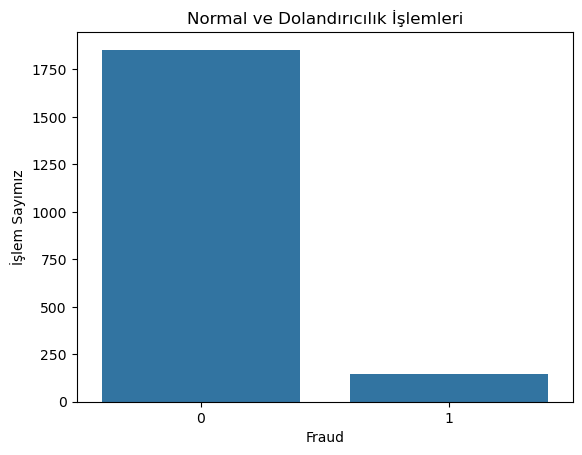

In [11]:
sns.countplot(
    data=df,
    x="fraud"
)
plt.title("Normal ve Dolandırıcılık İşlemleri")
plt.xlabel("Fraud")
plt.ylabel("İşlem Sayımız")
plt.show()

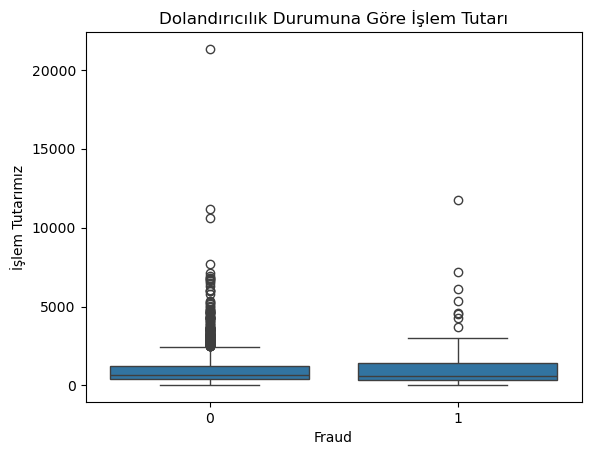

In [13]:
sns.boxplot(
    data=df,
    x="fraud",
    y="islem_tutari"
)
plt.title("Dolandırıcılık Durumuna Göre İşlem Tutarı")
plt.xlabel("Fraud")
plt.ylabel("İşlem Tutarımız")
plt.show()

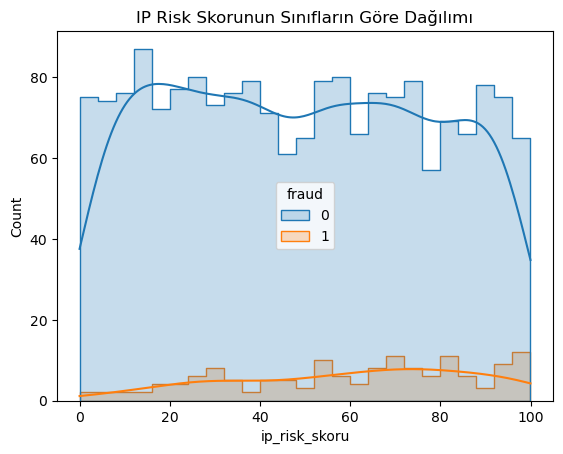

In [15]:
sns.histplot(
    data=df,
    x="ip_risk_skoru",
    hue="fraud",
    bins=25,
    kde=True,
    element="step"
)
plt.title("IP Risk Skorunun Sınıfların Göre Dağılımı")
plt.show()

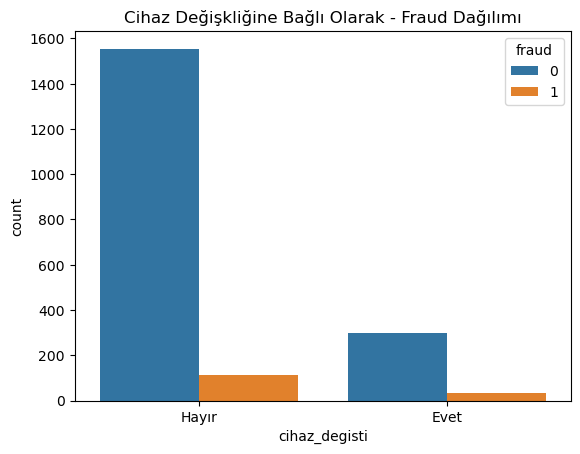

In [16]:
sns.countplot(
    data=df,
    x="cihaz_degisti",
    hue="fraud"
)
plt.title("Cihaz Değişkliğine Bağlı Olarak - Fraud Dağılımı")
plt.show()

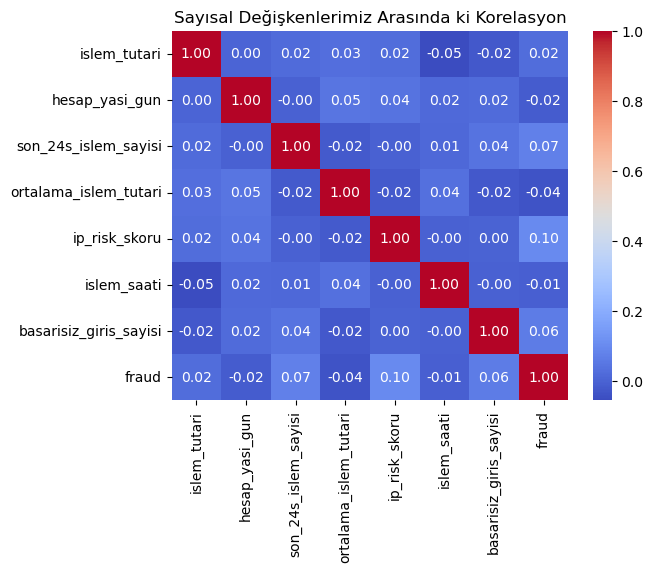

In [19]:
numeric_df = df.select_dtypes(
    include=["int64","float64"]
)


sns.heatmap(numeric_df.corr(),
           annot=True,
           cmap="coolwarm",
           fmt=".2f"
        )
plt.title("Sayısal Değişkenlerimiz Arasında ki Korelasyon")
plt.show()


In [21]:
X = df.drop("fraud",axis = 1)
y=df["fraud"]

In [22]:
numeric_features = [
    "islem_tutari",
    "hesap_yasi_gun",
    "son_24s_islem_sayisi",
    "ortalama_islem_tutari",
    "ip_risk_skoru",
    "islem_saati",
    "basarisiz_giris_sayisi"
]

categorical_features = [
    "cihaz_degisti",
    "ulke_farkli",
    "kart_tipi",
    "teslimat_adresi_farkli"
]

In [23]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [24]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

fraud
0    0.926875
1    0.073125
Name: proportion, dtype: float64
fraud
0    0.9275
1    0.0725
Name: proportion, dtype: float64


In [26]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median"))
    ]
)

In [27]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
    ]
)